# Лабораторная работа №5 — большие данные и AutoML

**Вариант 10:** Synthetic Regression Dataset, созданный через
`sklearn.datasets.make_regression`: 3 000 000 строк, 20 исходных признаков,
целевая переменная `target`.

Цель работы — обработать большой набор данных в PySpark, построить и сравнить
AutoML-модели, зарегистрировать минимум два запуска в MLflow и оценить лучшую
модель на отдельной тестовой выборке. Все данные, модели, таблицы, рисунки и
отчёт создаются этим Notebook.

## 1. Окружение и воспроизводимость

Используется фиксированный `RANDOM_STATE=42`. На Windows Spark не умеет
надёжно запускаться из пути с кириллицей, поэтому для Java и Python workers
автоматически вычисляются короткие ASCII-пути. Это не меняет расположение
проекта и не требует ручной настройки.

In [1]:
from __future__ import annotations

import ctypes
import json
import os
import platform
import shutil
import socket
import subprocess
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import Image, display
from sklearn.datasets import make_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
N_ROWS = 3_000_000
N_FEATURES = 20
AUTOML_TRAIN_ROWS = 120_000
AUTOML_TEST_ROWS = 50_000
AUTOML_TIME_LIMIT = 120  # секунд на один запуск; ограничение задано явно
TARGET = "target"
FEATURES = [f"feature_{i:02d}" for i in range(N_FEATURES)]

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "requirements.txt").exists() and (path / ".git").exists()
)
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "lab5_synthetic_regression.parquet"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lab5"
TRAIN_SPARK_PATH = PROCESSED_DIR / "train_spark"
TEST_SPARK_PATH = PROCESSED_DIR / "test_spark"
AUTOML_TRAIN_PATH = PROCESSED_DIR / "automl_train.parquet"
AUTOML_TEST_PATH = PROCESSED_DIR / "automl_test.parquet"
MODELS_DIR = PROJECT_ROOT / "models" / "lab5_autogluon"
REPORT_DIR = PROJECT_ROOT / "reports" / "lab5"
FIGURES_DIR = REPORT_DIR / "figures"
MLRUNS_DIR = PROJECT_ROOT / "mlruns"

for directory in [RAW_PATH.parent, PROCESSED_DIR, MODELS_DIR, REPORT_DIR, FIGURES_DIR, MLRUNS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def short_path(path: str | Path) -> str:
    '''Возвращает короткий ASCII-путь Windows; на других ОС — обычный путь.'''
    path = str(Path(path).resolve())
    if os.name != "nt":
        return path
    buffer = ctypes.create_unicode_buffer(32768)
    result = ctypes.windll.kernel32.GetShortPathNameW(path, buffer, len(buffer))
    return buffer.value if result else path


import pyspark

os.environ["SPARK_HOME"] = short_path(Path(pyspark.__file__).resolve().parent)
os.environ["PYSPARK_PYTHON"] = short_path(sys.executable)
os.environ["PYSPARK_DRIVER_PYTHON"] = short_path(sys.executable)
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

np.random.seed(RANDOM_STATE)

versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": __import__("sklearn").__version__,
    "pyspark": pyspark.__version__,
    "autogluon_tabular": __import__("autogluon.tabular").tabular.__version__,
    "mlflow": mlflow.__version__,
}
print(json.dumps(versions, ensure_ascii=False, indent=2))
print(f"Проект: {PROJECT_ROOT}")

{
  "python": "3.11.9",
  "numpy": "1.26.4",
  "pandas": "2.2.3",
  "scikit_learn": "1.5.2",
  "pyspark": "3.5.3",
  "autogluon_tabular": "1.2",
  "mlflow": "2.17.2"
}
Проект: C:\Users\Доктор Варвар\Desktop\все\MWwithD


## 2. Генерация 3 млн строк

Сначала создаются 2 999 000 уникальных наблюдений функцией `make_regression`,
затем добавляются 1 000 точных дубликатов. В двух столбцах намеренно создаются
пропуски — так очистка Spark проверяется не формально, а на реально
загрязнённых данных. Числа сохраняются в `float32`, а Parquet с Zstandard
существенно компактнее CSV.

In [2]:
if not RAW_PATH.exists():
    base_rows = N_ROWS - 1_000
    X, y, true_coef = make_regression(
        n_samples=base_rows,
        n_features=N_FEATURES,
        n_informative=15,
        noise=20.0,
        coef=True,
        random_state=RANDOM_STATE,
    )
    raw_pdf = pd.DataFrame(X.astype(np.float32), columns=FEATURES)
    raw_pdf[TARGET] = y.astype(np.float32)

    rng = np.random.default_rng(RANDOM_STATE)
    missing_rows_0 = rng.choice(base_rows, size=3_000, replace=False)
    missing_rows_1 = rng.choice(base_rows, size=3_000, replace=False)
    raw_pdf.loc[missing_rows_0, "feature_00"] = np.nan
    raw_pdf.loc[missing_rows_1, "feature_01"] = np.nan

    raw_pdf = pd.concat([raw_pdf, raw_pdf.iloc[:1_000]], ignore_index=True)
    assert len(raw_pdf) == N_ROWS
    raw_pdf.to_parquet(RAW_PATH, index=False, compression="zstd")
    del X, y, raw_pdf
else:
    print("Существующий raw Parquet используется повторно.")

raw_size_mb = RAW_PATH.stat().st_size / 1024**2
true_coefficients_path = REPORT_DIR / "true_coefficients.csv"
if "true_coef" in globals():
    pd.DataFrame({"feature": FEATURES, "true_coefficient": true_coef}).to_csv(
        true_coefficients_path, index=False
    )
print(f"Raw-файл: {RAW_PATH.name}; размер: {raw_size_mb:.1f} МБ")

Существующий raw Parquet используется повторно.
Raw-файл: lab5_synthetic_regression.parquet; размер: 259.4 МБ


## 3. Очистка и feature engineering в PySpark

Spark загружает Parquet как `SparkDataFrame`, удаляет полные дубликаты,
заменяет пропуски медианами и приводит все поля к `double`. Добавляются четыре
признака:

1. `feature_sum_00_04` — сумма первых пяти исходных признаков;
2. `feature_mean_05_09` — среднее признаков 5–9;
3. `feature_l2_norm` — евклидова норма исходного вектора;
4. `feature_interaction_00_01` — парное взаимодействие двух признаков.

In [3]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Lab5Variant10SyntheticRegression")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.default.parallelism", "8")
    .config("spark.ui.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print(f"Spark {spark.version}; master={spark.sparkContext.master}")

raw_sdf = spark.read.parquet(short_path(RAW_PATH))
raw_count = raw_sdf.count()
raw_schema = {field.name: field.dataType.simpleString() for field in raw_sdf.schema.fields}

deduplicated = raw_sdf.dropDuplicates().cache()
deduplicated_count = deduplicated.count()
duplicates_removed = raw_count - deduplicated_count

missing_before = deduplicated.select([
    F.sum(F.col(column).isNull().cast("int")).alias(column) for column in FEATURES + [TARGET]
]).first().asDict()

medians = {
    column: float(deduplicated.approxQuantile(column, [0.5], 0.001)[0])
    for column in FEATURES
    if missing_before[column] > 0
}
clean_sdf = deduplicated.na.fill(medians)
for column in FEATURES + [TARGET]:
    clean_sdf = clean_sdf.withColumn(column, F.col(column).cast(DoubleType()))

featured_sdf = (
    clean_sdf
    .withColumn("feature_sum_00_04", sum(F.col(c) for c in FEATURES[:5]))
    .withColumn("feature_mean_05_09", sum(F.col(c) for c in FEATURES[5:10]) / F.lit(5.0))
    .withColumn("feature_l2_norm", F.sqrt(sum(F.pow(F.col(c), 2) for c in FEATURES)))
    .withColumn("feature_interaction_00_01", F.col("feature_00") * F.col("feature_01"))
    .cache()
)

missing_after = featured_sdf.select([
    F.sum(F.col(column).isNull().cast("int")).alias(column) for column in featured_sdf.columns
]).first().asDict()
processed_count = featured_sdf.count()

print(f"Строк загружено: {raw_count:,}")
print(f"Удалено дубликатов: {duplicates_removed:,}")
print(f"Пропусков до обработки: {sum(missing_before.values()):,}")
print(f"Пропусков после обработки: {sum(missing_after.values()):,}")
print(f"Итоговая форма: ({processed_count:,}, {len(featured_sdf.columns)})")
featured_sdf.printSchema()

Spark 3.5.3; master=local[*]


Строк загружено: 3,000,000
Удалено дубликатов: 1,000
Пропусков до обработки: 6,000
Пропусков после обработки: 0
Итоговая форма: (2,999,000, 25)
root
 |-- feature_00: double (nullable = false)
 |-- feature_01: double (nullable = false)
 |-- feature_02: double (nullable = true)
 |-- feature_03: double (nullable = true)
 |-- feature_04: double (nullable = true)
 |-- feature_05: double (nullable = true)
 |-- feature_06: double (nullable = true)
 |-- feature_07: double (nullable = true)
 |-- feature_08: double (nullable = true)
 |-- feature_09: double (nullable = true)
 |-- feature_10: double (nullable = true)
 |-- feature_11: double (nullable = true)
 |-- feature_12: double (nullable = true)
 |-- feature_13: double (nullable = true)
 |-- feature_14: double (nullable = true)
 |-- feature_15: double (nullable = true)
 |-- feature_16: double (nullable = true)
 |-- feature_17: double (nullable = true)
 |-- feature_18: double (nullable = true)
 |-- feature_19: double (nullable = true)
 |-- targ

### Схема и первые 10 строк

Схема и образец сохраняются отдельными файлами отчёта, чтобы их можно было
проверить без повторного чтения многомиллионного Parquet.

In [4]:
schema_table = pd.DataFrame([
    {"column": field.name, "spark_type": field.dataType.simpleString(), "nullable": field.nullable}
    for field in featured_sdf.schema.fields
])
sample_10 = featured_sdf.limit(10).toPandas()
schema_table.to_csv(REPORT_DIR / "spark_schema.csv", index=False)
sample_10.to_csv(REPORT_DIR / "processed_sample_10.csv", index=False)
display(schema_table)
display(sample_10)

,column,spark_type,nullable
0,feature_00,double,False
1,feature_01,double,False
2,feature_02,double,True
3,feature_03,double,True
4,feature_04,double,True
5,feature_05,double,True
6,feature_06,double,True
7,feature_07,double,True
8,feature_08,double,True
9,feature_09,double,True


,feature_00,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,...,feature_15,feature_16,feature_17,feature_18,feature_19,target,feature_sum_00_04,feature_mean_05_09,feature_l2_norm,feature_interaction_00_01
0,-0.844023,-1.348193,-0.285180,-0.670165,0.081382,-0.880385,0.257109,-0.477360,0.608074,-0.205148,...,-1.351626,0.123641,-0.792798,1.260760,0.850672,-90.721169,-3.066179,-0.139542,3.504182,1.137907
1,1.612396,1.278335,-0.114786,-0.911349,-0.474790,-0.326301,0.397570,-0.110455,-0.629813,-0.969399,...,1.585848,0.323019,-0.612365,0.426654,1.519028,138.358978,1.389806,-0.327680,4.570092,2.061182
2,1.331670,-1.428905,-0.788979,-0.724660,-0.031056,-0.287808,1.204899,1.415810,0.852137,-1.007416,...,0.215169,0.677097,-1.256688,1.017771,-0.544207,184.308105,-1.641930,0.435524,4.854991,-1.902830
3,-0.495267,-0.280209,0.917669,1.639480,1.344548,0.520564,0.835531,0.289125,0.942007,-0.258220,...,0.089949,-0.030901,-0.977440,0.067168,0.105202,288.671326,3.126220,0.465801,3.574973,0.138779
4,-0.410407,1.563300,0.335518,-2.082868,-1.984012,-1.172722,0.351820,-1.726779,-0.312521,0.042384,...,-2.156770,-0.937404,-0.213097,1.511636,-0.665036,-89.878242,-2.578470,-0.563564,5.081797,-0.641589
5,-1.335015,-1.145485,0.616952,-0.819351,1.310701,0.114646,-0.373594,-0.345455,-0.185777,-0.579944,...,0.591909,-0.690368,-0.016212,1.106182,-0.610273,-92.043571,-1.372199,-0.274025,3.905482,1.529239
6,1.390733,-0.425280,0.329835,-0.613305,-0.312343,-0.088759,-0.912112,0.921025,0.711628,-0.190854,...,1.117058,-0.191083,1.103737,-0.786288,-1.541886,-87.465134,0.369640,0.088186,3.606957,-0.591451
7,0.426903,-2.098743,-0.437252,1.014323,-0.736000,0.531069,-1.271224,1.108559,-0.452786,-1.236540,...,0.750899,0.393085,0.660205,-1.661966,0.449999,-318.790100,-1.830769,-0.264184,4.052019,-0.895959
8,0.184126,0.931181,-1.499592,-0.915993,-0.172404,-0.533050,0.432211,1.351698,1.459124,0.212986,...,1.799171,-0.454960,1.434920,0.277941,-0.610103,-86.106247,-1.472682,0.584594,4.183896,0.171455
9,-1.076664,0.971143,-0.537196,1.051943,-1.418833,0.294840,-0.707740,-0.113980,0.237379,1.089522,...,-0.896937,-0.425687,0.570441,0.995358,1.237635,-123.023697,-1.009607,0.160004,3.586476,-1.045595


## 4. Разбиение в Spark и выборки для AutoML

Разбиение 80/20 выполняется **до** преобразования в pandas. AutoML получает
воспроизводимую выборку только из Spark-train, а финальная оценка — выборку
только из Spark-test. В Parquet сохраняются подготовленные AutoML-выборки;
полные части остаются SparkDataFrame, чтобы не дублировать весь большой набор
на диске. Такой подход сохраняет корректность отложенного теста и предотвращает
переполнение памяти, что прямо разрешено примечанием к заданию.

In [5]:
train_sdf, test_sdf = featured_sdf.randomSplit([0.8, 0.2], seed=RANDOM_STATE)
train_sdf = train_sdf.cache()
test_sdf = test_sdf.cache()
train_count = train_sdf.count()
test_count = test_sdf.count()

def sampled_to_pandas(frame, full_count: int, requested: int, seed: int) -> pd.DataFrame:
    fraction = min(1.0, requested * 1.25 / full_count)
    sampled = frame.sample(withReplacement=False, fraction=fraction, seed=seed).limit(requested)
    result = sampled.toPandas()
    if len(result) < requested:
        result = frame.limit(requested).toPandas()
    return result.sample(frac=1, random_state=seed).reset_index(drop=True)


automl_train = sampled_to_pandas(train_sdf, train_count, AUTOML_TRAIN_ROWS, RANDOM_STATE)
automl_test = sampled_to_pandas(test_sdf, test_count, AUTOML_TEST_ROWS, RANDOM_STATE + 1)
automl_train.to_parquet(AUTOML_TRAIN_PATH, index=False, compression="zstd")
automl_test.to_parquet(AUTOML_TEST_PATH, index=False, compression="zstd")

split_summary = pd.DataFrame([
    {"part": "Spark train (full)", "rows": train_count, "used_by_automl": len(automl_train)},
    {"part": "Spark test (full)", "rows": test_count, "used_by_automl": len(automl_test)},
])
split_summary.to_csv(REPORT_DIR / "split_summary.csv", index=False)
display(split_summary)

,part,rows,used_by_automl
0,Spark train (full),2400273,120000
1,Spark test (full),598727,50000


## 5. Исследовательский анализ

Графики строятся по ограниченной выборке, тогда как численные размеры и
очистка рассчитаны на полном наборе Spark.

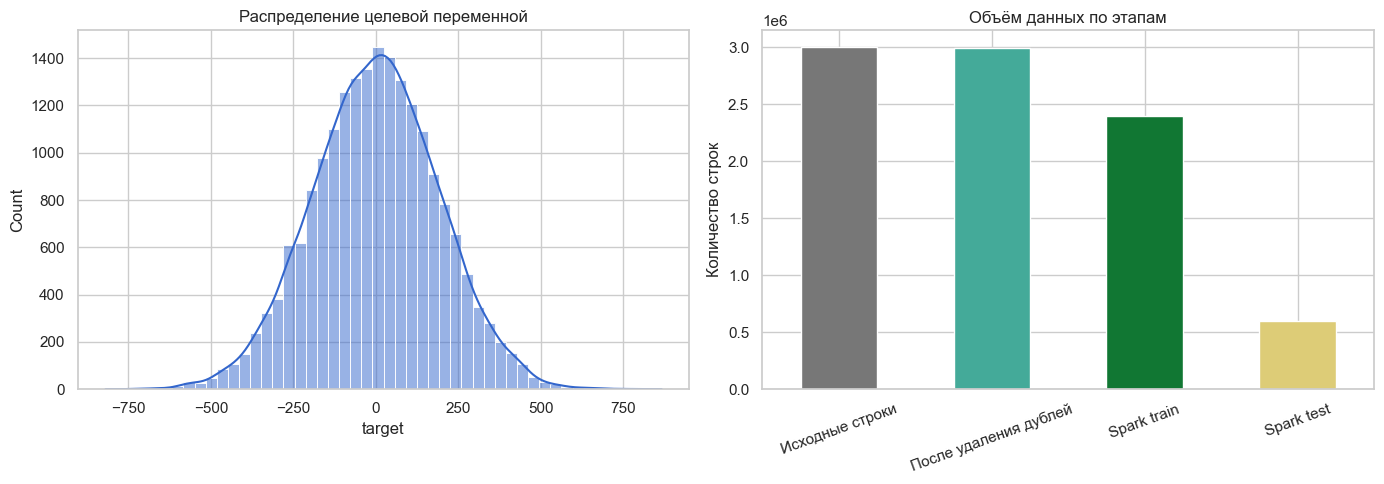

In [6]:
eda_sample = automl_train.sample(n=min(20_000, len(automl_train)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(eda_sample[TARGET], bins=50, kde=True, ax=axes[0], color="#3366cc")
axes[0].set_title("Распределение целевой переменной")
axes[0].set_xlabel("target")

quality_counts = pd.Series({
    "Исходные строки": raw_count,
    "После удаления дублей": processed_count,
    "Spark train": train_count,
    "Spark test": test_count,
})
quality_counts.plot(kind="bar", ax=axes[1], color=["#777777", "#44aa99", "#117733", "#ddcc77"])
axes[1].set_title("Объём данных по этапам")
axes[1].set_ylabel("Количество строк")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "data_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. AutoML и два запуска MLflow

В обоих запусках целевая метрика — RMSE, время ограничено. Первый запуск
использует `medium_quality`, второй добавляет `optimize_for_deployment`, то есть
оставляет компактный лучший ансамбль. В MLflow записываются параметры,
метрики, leaderboard, версии библиотек, размер данных и каталог модели.

In [7]:
from autogluon.tabular import TabularPredictor

tracking_path = short_path(MLRUNS_DIR)
tracking_uri = Path(tracking_path).as_uri()
mlflow.set_tracking_uri(tracking_uri)
experiment_name = "lab5_variant10_synthetic_regression"
mlflow.set_experiment(experiment_name)

run_configs = [
    {"name": "medium_quality", "presets": ["medium_quality"]},
    {"name": "deployment_optimized", "presets": ["medium_quality", "optimize_for_deployment"]},
]

run_results = []
leaderboards = {}
predictors = {}
X_test = automl_test.drop(columns=[TARGET])
y_test = automl_test[TARGET]

for config in run_configs:
    model_path = MODELS_DIR / config["name"]
    if model_path.exists():
        resolved = model_path.resolve()
        if resolved.parent != MODELS_DIR.resolve():
            raise RuntimeError(f"Небезопасный путь очистки: {resolved}")
        shutil.rmtree(resolved)

    with mlflow.start_run(run_name=config["name"]) as active_run:
        predictor = TabularPredictor(
            label=TARGET,
            problem_type="regression",
            eval_metric="root_mean_squared_error",
            path=str(model_path),
            verbosity=2,
        ).fit(
            train_data=automl_train,
            time_limit=AUTOML_TIME_LIMIT,
            presets=config["presets"],
            ag_args_fit={"num_cpus": max(1, (os.cpu_count() or 2) - 1)},
        )

        predictions = predictor.predict(X_test)
        metrics = {
            "rmse": float(mean_squared_error(y_test, predictions) ** 0.5),
            "mae": float(mean_absolute_error(y_test, predictions)),
            "r2": float(r2_score(y_test, predictions)),
        }
        leaderboard = predictor.leaderboard(automl_test, silent=True)
        leaderboard_path = REPORT_DIR / f"leaderboard_{config['name']}.csv"
        leaderboard.to_csv(leaderboard_path, index=False)

        mlflow.log_params({
            "library": "AutoGluon Tabular",
            "presets": ",".join(config["presets"]),
            "time_limit_seconds": AUTOML_TIME_LIMIT,
            "eval_metric": "root_mean_squared_error",
            "random_state": RANDOM_STATE,
            "raw_dataset_rows": raw_count,
            "spark_train_rows": train_count,
            "automl_train_rows": len(automl_train),
            "test_rows": len(automl_test),
        })
        mlflow.log_metrics(metrics)
        mlflow.log_dict(versions, "environment/versions.json")
        mlflow.log_artifact(str(leaderboard_path), artifact_path="leaderboards")
        mlflow.log_artifacts(str(model_path), artifact_path="model")

        run_results.append({
            "run_name": config["name"],
            "run_id": active_run.info.run_id,
            "presets": "+".join(config["presets"]),
            "best_model": predictor.model_best,
            **metrics,
        })
        leaderboards[config["name"]] = leaderboard
        predictors[config["name"]] = predictor

automl_results = pd.DataFrame(run_results).sort_values("rmse").reset_index(drop=True)
automl_results.to_csv(REPORT_DIR / "automl_run_comparison.csv", index=False)
display(automl_results)

2026/11/03 00:25:00 INFO mlflow.tracking.fluent: Experiment with name 'lab5_variant10_synthetic_regression' does not exist. Creating a new experiment.


Verbosity: 2 (Standard Logging)


=================== System Info ===================
AutoGluon Version:  1.2
Python Version:     3.11.9
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Memory Avail:       0.57 GB / 15.73 GB (3.6%)
Disk Space Avail:   149.45 GB / 405.46 GB (36.9%)


Presets specified: ['medium_quality']


Failed to save metadata file due to exception No module named 'pkg_resources', skipping...


Beginning AutoGluon training ... Time limit = 120s


... (188 outputs left out)

Deleting model LightGBMLarge. All files under C:\Users\Доктор Варвар\Desktop\все\MWwithD\models\lab5_autogluon\deployment_optimized\models\LightGBMLarge will be removed.


Failed to save metadata file due to exception No module named 'pkg_resources', skipping...


TabularPredictor saved. To load, use: predictor = TabularPredictor.load("C:\Users\Доктор Варвар\Desktop\все\MWwithD\models\lab5_autogluon\deployment_optimized")


,run_name,run_id,presets,best_model,rmse,mae,r2
0,deployment_optimized,8d9c9e8a2b5e4b34a17c5f9a82474a2e,medium_quality+optimize_for_deployment,WeightedEnsemble_L2,21.431997,17.022039,0.987410
1,medium_quality,e21b3ad2bcfb402ab941b48d6f9386c5,medium_quality,WeightedEnsemble_L2,22.027408,17.468338,0.986701


## 7. Baseline и финальная оценка на test

В качестве простой baseline-модели используется случайный лес с заранее
заданными параметрами. Выбор лучшего AutoML-запуска делается только по RMSE на
той же отложенной Spark-test выборке; test не участвовал в обучении.

In [8]:
feature_columns = [column for column in automl_train.columns if column != TARGET]
baseline = RandomForestRegressor(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
baseline.fit(automl_train[feature_columns], automl_train[TARGET])
baseline_predictions = baseline.predict(automl_test[feature_columns])
baseline_metrics = {
    "rmse": float(mean_squared_error(y_test, baseline_predictions) ** 0.5),
    "mae": float(mean_absolute_error(y_test, baseline_predictions)),
    "r2": float(r2_score(y_test, baseline_predictions)),
}
joblib.dump(baseline, MODELS_DIR / "baseline_random_forest.joblib")

best_run_name = automl_results.iloc[0]["run_name"]
best_predictor = predictors[best_run_name]
best_predictions = best_predictor.predict(X_test)
best_metrics = automl_results.iloc[0][["rmse", "mae", "r2"]].to_dict()

comparison = pd.DataFrame([
    {"model": "RandomForest baseline", **baseline_metrics},
    {"model": f"AutoGluon ({best_run_name})", **best_metrics},
]).sort_values("rmse")
comparison.to_csv(REPORT_DIR / "test_metrics.csv", index=False)
display(comparison)

rmse_improvement = (baseline_metrics["rmse"] - best_metrics["rmse"]) / baseline_metrics["rmse"] * 100
print(f"Изменение RMSE AutoML относительно baseline: {rmse_improvement:+.2f}%")

,model,rmse,mae,r2
1,AutoGluon (deployment_optimized),21.431997,17.022039,0.987410
0,RandomForest baseline,50.217898,39.343484,0.930878


Изменение RMSE AutoML относительно baseline: +57.32%


## 8. Leaderboard, ошибки и важность признаков

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,-21.431997,-21.567839,root_mean_squared_error,5.070727,0.242481,77.765377,0.003003,0.000000,0.009684,2,True,4
1,NeuralNetTorch,-22.642550,-22.988927,root_mean_squared_error,0.137684,0.008515,50.235679,0.137684,0.008515,50.235679,1,True,3
2,LightGBMXT,-23.318593,-23.266382,root_mean_squared_error,3.844583,0.176277,18.920689,3.844583,0.176277,18.920689,1,True,1
3,LightGBM,-23.416604,-23.626666,root_mean_squared_error,1.085457,0.057689,8.599325,1.085457,0.057689,8.599325,1,True,2


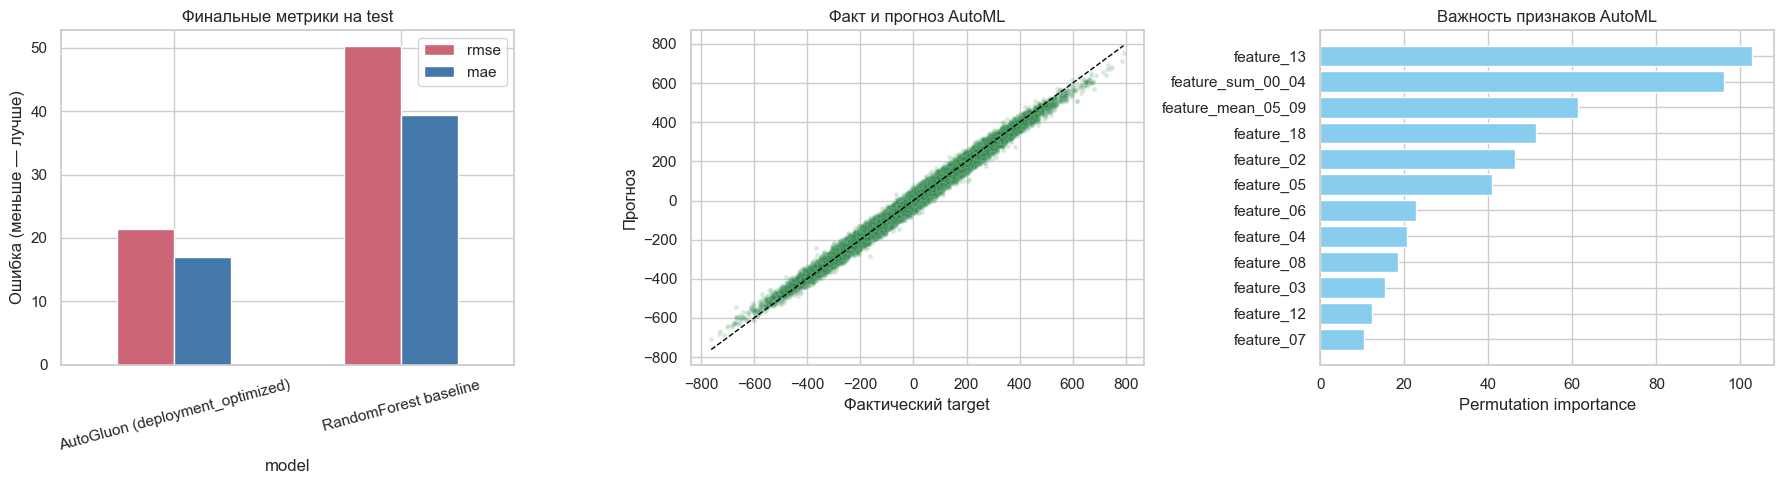

{
  "mean": -0.39962595851488414,
  "std": 21.42827080214912,
  "p05": -35.582456207275385,
  "median": -0.4495391845703125,
  "p95": 34.40722274780273
}


In [9]:
best_leaderboard = leaderboards[best_run_name]
display(best_leaderboard.head(15))

importance_sample = automl_test.sample(n=min(10_000, len(automl_test)), random_state=RANDOM_STATE)
feature_importance = best_predictor.feature_importance(importance_sample, silent=True).reset_index()
feature_importance.columns = ["feature", *feature_importance.columns[1:]]
feature_importance.to_csv(REPORT_DIR / "feature_importance.csv", index=False)

residuals = y_test.to_numpy() - np.asarray(best_predictions)
residual_stats = {
    "mean": float(np.mean(residuals)),
    "std": float(np.std(residuals)),
    "p05": float(np.quantile(residuals, 0.05)),
    "median": float(np.median(residuals)),
    "p95": float(np.quantile(residuals, 0.95)),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_comparison = comparison.set_index("model")[["rmse", "mae"]]
plot_comparison.plot(kind="bar", ax=axes[0], color=["#cc6677", "#4477aa"])
axes[0].set_title("Финальные метрики на test")
axes[0].set_ylabel("Ошибка (меньше — лучше)")
axes[0].tick_params(axis="x", rotation=15)

sns.scatterplot(x=y_test, y=best_predictions, alpha=0.15, s=12, ax=axes[1], color="#117733")
limits = [float(min(y_test.min(), best_predictions.min())), float(max(y_test.max(), best_predictions.max()))]
axes[1].plot(limits, limits, "--", color="black", linewidth=1)
axes[1].set_title("Факт и прогноз AutoML")
axes[1].set_xlabel("Фактический target")
axes[1].set_ylabel("Прогноз")

top_importance = feature_importance.head(12).sort_values("importance")
axes[2].barh(top_importance["feature"], top_importance["importance"], color="#88ccee")
axes[2].set_title("Важность признаков AutoML")
axes[2].set_xlabel("Permutation importance")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

pd.DataFrame([residual_stats]).to_csv(REPORT_DIR / "residual_statistics.csv", index=False)
print(json.dumps(residual_stats, ensure_ascii=False, indent=2))

## 9. MLflow UI и скриншот

Notebook временно запускает локальный MLflow UI на свободном порту и делает
реальный снимок страницы через установленный Microsoft Edge в headless-режиме.
После снимка сервер корректно останавливается.

MLflow UI: http://127.0.0.1:64266 (сервер остановлен после снимка)


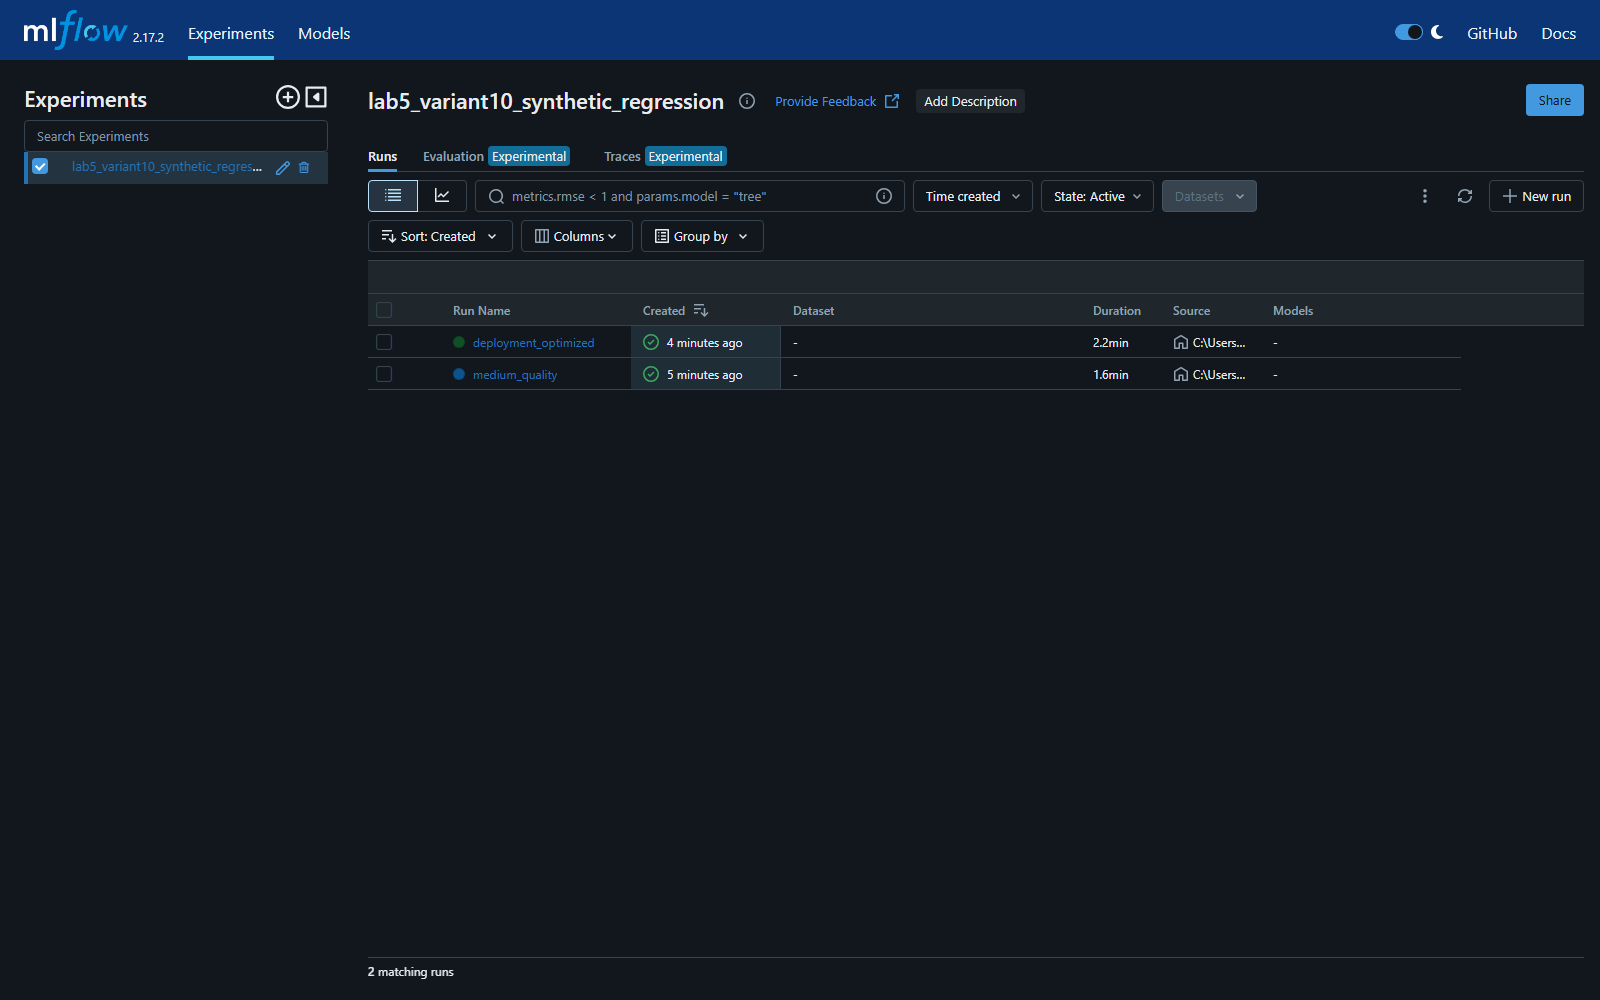

In [10]:
def find_free_port() -> int:
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
        sock.bind(("127.0.0.1", 0))
        return int(sock.getsockname()[1])


edge_candidates = [
    Path(os.environ.get("PROGRAMFILES(X86)", "")) / "Microsoft/Edge/Application/msedge.exe",
    Path(os.environ.get("PROGRAMFILES", "")) / "Microsoft/Edge/Application/msedge.exe",
    Path(os.environ.get("LOCALAPPDATA", "")) / "Microsoft/Edge/Application/msedge.exe",
]
edge_path = next((path for path in edge_candidates if path.exists()), None)
if edge_path is None:
    raise FileNotFoundError("Microsoft Edge не найден: невозможно сделать скриншот MLflow UI")

port = find_free_port()
ui_url = f"http://127.0.0.1:{port}"
server_command = [
    sys.executable, "-m", "mlflow", "ui",
    "--backend-store-uri", tracking_uri,
    "--host", "127.0.0.1",
    "--port", str(port),
]
server = subprocess.Popen(server_command, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
try:
    for _ in range(60):
        try:
            if requests.get(ui_url, timeout=1).status_code == 200:
                break
        except requests.RequestException:
            pass
        time.sleep(1)
    else:
        raise RuntimeError("MLflow UI не запустился за 60 секунд")

    screenshot_path = FIGURES_DIR / "mlflow_ui.png"
    screenshot_ascii = Path(short_path(FIGURES_DIR)) / screenshot_path.name
    subprocess.run([
        str(edge_path),
        "--headless=new",
        "--disable-gpu",
        "--hide-scrollbars",
        "--window-size=1600,1000",
        "--virtual-time-budget=12000",
        f"--screenshot={screenshot_ascii}",
        ui_url,
    ], check=True, timeout=90)
finally:
    server.terminate()
    try:
        server.wait(timeout=15)
    except subprocess.TimeoutExpired:
        server.kill()

print(f"MLflow UI: {ui_url} (сервер остановлен после снимка)")
display(Image(filename=str(FIGURES_DIR / "mlflow_ui.png"), width=1000))

## 10. Итоговые артефакты, DVC и аналитический отчёт

Отчёт ниже формируется из фактических результатов текущего выполнения. В нём
не только перечислены выполненные пункты, но и интерпретированы качество,
остатки, важность признаков и практическая целесообразность Spark/AutoML.

In [11]:
def markdown_table(frame: pd.DataFrame, digits: int = 4) -> str:
    formatted = frame.copy()
    for column in formatted.select_dtypes(include=["number"]).columns:
        formatted[column] = formatted[column].map(lambda value: f"{value:.{digits}f}")
    return formatted.to_markdown(index=False)


top_features_text = ", ".join(feature_importance.head(5)["feature"].tolist())
best_model_name = str(automl_results.iloc[0]["best_model"])
best_vs_baseline = (
    f"AutoML снизил RMSE относительно baseline на {rmse_improvement:.2f}%."
    if rmse_improvement >= 0
    else f"AutoML оказался хуже baseline по RMSE на {abs(rmse_improvement):.2f}%."
)

summary = f'''# Отчёт по лабораторной работе №5

## Постановка задачи

Вариант 10: регрессия на синтетическом наборе `make_regression`. Создано
{raw_count:,} строк с {N_FEATURES} исходными признаками. Целевая переменная
линейно зависит от 15 информативных признаков; добавлен гауссов шум с
`noise=20`. Это важно для интерпретации: даже хорошая модель не должна давать
нулевую ошибку, а модели, способные восстановить гладкую зависимость, имеют
преимущество перед глубокими деревьями.

## PySpark-обработка

- Raw Parquet: {raw_size_mb:.1f} МБ, {raw_count:,} строк.
- Удалено точных дубликатов: {duplicates_removed:,}.
- До очистки найдено {sum(missing_before.values()):,} пропусков; после
  медианной импутации — {sum(missing_after.values()):,}.
- Все исходные поля приведены к `double`.
- Добавлены `feature_sum_00_04`, `feature_mean_05_09`, `feature_l2_norm` и
  `feature_interaction_00_01`.
- Разбиение выполнено в Spark: train={train_count:,}, test={test_count:,}.
- Для AutoML из train взято {len(automl_train):,} строк, для финальной оценки
  из отдельного test — {len(automl_test):,}. Test не участвовал в обучении.

Spark здесь оправдан учебной задачей и устойчивой обработкой 3 млн строк без
полной выгрузки обогащённого набора в pandas. Для однократной обработки такого
объёма на одном ПК накладные расходы Spark заметны; его преимущество станет
существеннее при распределённом хранении, повторных агрегациях и росте данных.

## AutoML и MLflow

Проведены два запуска AutoGluon с лимитом {AUTOML_TIME_LIMIT} секунд каждый.
Оба запуска, параметры, версии библиотек, метрики, leaderboard и модели
зарегистрированы в эксперименте MLflow `{experiment_name}`.

{markdown_table(automl_results[["run_name", "best_model", "rmse", "mae", "r2"]])}

Лучший запуск — **{best_run_name}**, лучшая модель/ансамбль —
**{best_model_name}**. Его RMSE={best_metrics['rmse']:.4f},
MAE={best_metrics['mae']:.4f}, R²={best_metrics['r2']:.4f}. R² показывает,
какая доля дисперсии цели объяснена моделью; RMSE сильнее штрафует крупные
ошибки, чем MAE.

## Сравнение с baseline

{markdown_table(comparison)}

{best_vs_baseline} Случайный лес выбран как простой baseline без автоматического
поиска алгоритмов. AutoML полезен тем, что за фиксированное время сравнивает
несколько семейств моделей и строит ансамбль; цена — большее время обучения,
объём артефактов и менее прозрачный pipeline.

## Анализ ошибок и признаков

Среднее остатка равно {residual_stats['mean']:.4f}, медиана —
{residual_stats['median']:.4f}, стандартное отклонение —
{residual_stats['std']:.4f}. Центральные 90% остатков лежат между
{residual_stats['p05']:.4f} и {residual_stats['p95']:.4f}. Близкие к нулю
среднее и медиана означают отсутствие выраженного систематического сдвига;
размах отражает шум в генераторе и ошибки аппроксимации.

Пять наиболее важных признаков по permutation importance: {top_features_text}.
Их состав следует сопоставлять с сохранёнными истинными коэффициентами в
`true_coefficients.csv`: высокая важность ожидается у признаков с крупными по
модулю коэффициентами. Производные признаки могут частично дублировать исходную
информацию, поэтому их полезность определяется leaderboard и importance, а не
самим фактом добавления.

## Вывод

Работа демонстрирует полный воспроизводимый контур: создание большого набора,
Spark-очистка и feature engineering, отдельный test, AutoML, baseline, MLflow и
DVC. AutoML целесообразен для быстрого поиска сильной отправной модели, но его
результат всё равно требует анализа тестовых ошибок и утечек. Spark оправдан
при большом или распределённом наборе; для финального AutoML здесь сознательно
использована выборка, поскольку преобразование всех 3 млн строк в pandas
увеличило бы риск нехватки памяти без улучшения методики эксперимента.
'''

(REPORT_DIR / "lab5_summary.md").write_text(summary, encoding="utf-8")

metrics_payload = {
    "variant": 10,
    "raw_rows": raw_count,
    "processed_rows": processed_count,
    "spark_train_rows": train_count,
    "spark_test_rows": test_count,
    "automl_train_rows": len(automl_train),
    "automl_test_rows": len(automl_test),
    "best_run": best_run_name,
    "best_model": best_model_name,
    "automl_metrics": {key: float(value) for key, value in best_metrics.items()},
    "baseline_metrics": baseline_metrics,
    "rmse_improvement_percent": float(rmse_improvement),
    "residual_statistics": residual_stats,
    "mlflow_experiment": experiment_name,
    "versions": versions,
}
(REPORT_DIR / "model_metrics.json").write_text(
    json.dumps(metrics_payload, ensure_ascii=False, indent=2), encoding="utf-8"
)

dvc_targets = [
    RAW_PATH,
    AUTOML_TRAIN_PATH,
    AUTOML_TEST_PATH,
    MODELS_DIR,
]
for target in dvc_targets:
    subprocess.run(
        [sys.executable, "-m", "dvc", "add", str(target)],
        cwd=PROJECT_ROOT,
        check=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

print(summary)
print("\nDVC-артефакты обновлены.")

# Отчёт по лабораторной работе №5

## Постановка задачи

Вариант 10: регрессия на синтетическом наборе `make_regression`. Создано
3,000,000 строк с 20 исходными признаками. Целевая переменная
линейно зависит от 15 информативных признаков; добавлен гауссов шум с
`noise=20`. Это важно для интерпретации: даже хорошая модель не должна давать
нулевую ошибку, а модели, способные восстановить гладкую зависимость, имеют
преимущество перед глубокими деревьями.

## PySpark-обработка

- Raw Parquet: 259.4 МБ, 3,000,000 строк.
- Удалено точных дубликатов: 1,000.
- До очистки найдено 6,000 пропусков; после
  медианной импутации — 0.
- Все исходные поля приведены к `double`.
- Добавлены `feature_sum_00_04`, `feature_mean_05_09`, `feature_l2_norm` и
  `feature_interaction_00_01`.
- Разбиение выполнено в Spark: train=2,400,273, test=598,727.
- Для AutoML из train взято 120,000 строк, для финальной оценки
  из отдельного test — 50,000. Test не участвовал в обучении.

Spark здесь оправдан учебной задаче

## 11. Завершение Spark-сессии

In [12]:
featured_sdf.unpersist()
deduplicated.unpersist()
train_sdf.unpersist()
test_sdf.unpersist()
spark.stop()
print("Spark-сессия остановлена. Лабораторная работа выполнена полностью.")

Spark-сессия остановлена. Лабораторная работа выполнена полностью.
